# Piloto exploratorio recencia_h2: resultados auditados

Orden: preflight→piloto→auditar→resultados→generar_notebook. Este notebook solo lee
resultados completos; no ajusta modelos. Entorno Python3.12.14/sklearn1.9.1, lock54,
semilla20261010 del piloto. Todos2021–2025 vistos; sin confirmación independiente ni
causalidad. Entradas: resultados/meta.json, auditoría, tablas y gráficos propios.
Fuente editable: fuentes/01_resultados.py. Celdas realmente ejecutadas mediante exec.


In [1]:
"""Resultados auditados del piloto recencia_h2; no ejecuta ajustes."""
from pathlib import Path
import json
import pandas as pd
ROOT = Path('/home/kelium/Documents/espcarlos/icfes-predict-improved')
OUT = ROOT/'experimentos_temporales_objetivo3_v1/etapa2/resultados'
meta=json.loads((OUT/'meta.json').read_text())
assert json.loads((OUT/'auditoria_independiente.json').read_text())['aprobado']
print('Exploratorio: todos2021–2025 vistos; sin causalidad/confirmación independiente')
print(json.dumps(meta,ensure_ascii=False,indent=2))

Exploratorio: todos2021–2025 vistos; sin causalidad/confirmación independiente
{
  "primario": "recencia_h2/global",
  "n": 165,
  "mae_persistencia": 3.429267191379531,
  "mae_recencia_global": 3.429267191379531,
  "mejora_porcentaje": 0.0,
  "umbral_original": 5,
  "cumple": false,
  "delta_mae_v5": 0.0,
  "exploratorio": true,
  "confirmacion_independiente": false,
  "causalidad": false
}


In [2]:
metricas=pd.read_csv(OUT/'tablas/metricas_externas.csv',dtype={'codigo_departamento':str},float_precision='round_trip')
print(metricas[metricas.corte=='global'][['procedimiento','n','mae','rmse','sesgo','delta_mae']].to_string(index=False))

procedimiento   n      mae     rmse     sesgo  delta_mae
       global 165 3.429267 4.314921 -2.096011        0.0
    historico 165 3.429267 4.314921 -2.096011        0.0
    nivel_ipm 165 3.429267 4.314921 -2.096011        0.0
   cambio_ipm 165 3.429267 4.314921 -2.096011        0.0
 cambio_tasas 165 3.429267 4.314921 -2.096011        0.0
 cambio_ambas 165 3.429267 4.314921 -2.096011        0.0
 persistencia 165 3.429267 4.314921 -2.096011        0.0


In [3]:
selecciones=pd.read_csv(OUT/'tablas/selecciones.csv')
print(selecciones.to_string(index=False))

 anio procedimiento           id              seleccion
 2021        global persistencia    fija sin puntuación
 2021     historico persistencia    fija sin puntuación
 2021     nivel_ipm persistencia    fija sin puntuación
 2021    cambio_ipm persistencia    fija sin puntuación
 2021  cambio_tasas persistencia    fija sin puntuación
 2021  cambio_ambas persistencia    fija sin puntuación
 2021  persistencia persistencia    fija sin puntuación
 2022        global persistencia internas antes externo
 2022     historico persistencia internas antes externo
 2022     nivel_ipm persistencia internas antes externo
 2022    cambio_ipm persistencia internas antes externo
 2022  cambio_tasas persistencia internas antes externo
 2022  cambio_ambas persistencia internas antes externo
 2022  persistencia persistencia internas antes externo
 2023        global persistencia internas antes externo
 2023     historico persistencia internas antes externo
 2023     nivel_ipm persistencia internas antes 

In [4]:
registros=pd.read_csv(OUT/'tablas/registros_144.csv',float_precision='round_trip')
assert len(registros)==144 and registros.id.nunique()==36
print(registros.groupby(['externo','estado']).size().to_string())
print('11880 originales;4752 únicas condicionadas a copias/contexto exactos;1155 externas')

externo  estado  
2022     completo    36
2023     completo    36
2024     completo    36
2025     completo    36
11880 originales;4752 únicas condicionadas a copias/contexto exactos;1155 externas


In [5]:
print(metricas[(metricas.procedimiento=='global')&metricas.corte.isin(['anio','2021–2024','2025'])][['corte','anio','n','mae','rmse','sesgo','delta_mae']].to_string(index=False))

    corte   anio   n      mae     rmse     sesgo  delta_mae
     anio 2021.0  33 2.640224 3.509749  1.407090        0.0
     anio 2022.0  33 5.091966 5.553520 -4.506233        0.0
     anio 2023.0  33 3.207272 4.010836 -2.250916        0.0
     anio 2024.0  33 3.960279 4.921069 -3.635062        0.0
     anio 2025.0  33 2.246595 3.103071 -1.494932        0.0
2021–2024    NaN 132 3.724935 4.567922 -2.246280        0.0
     2025    NaN  33 2.246595 3.103071 -1.494932        0.0


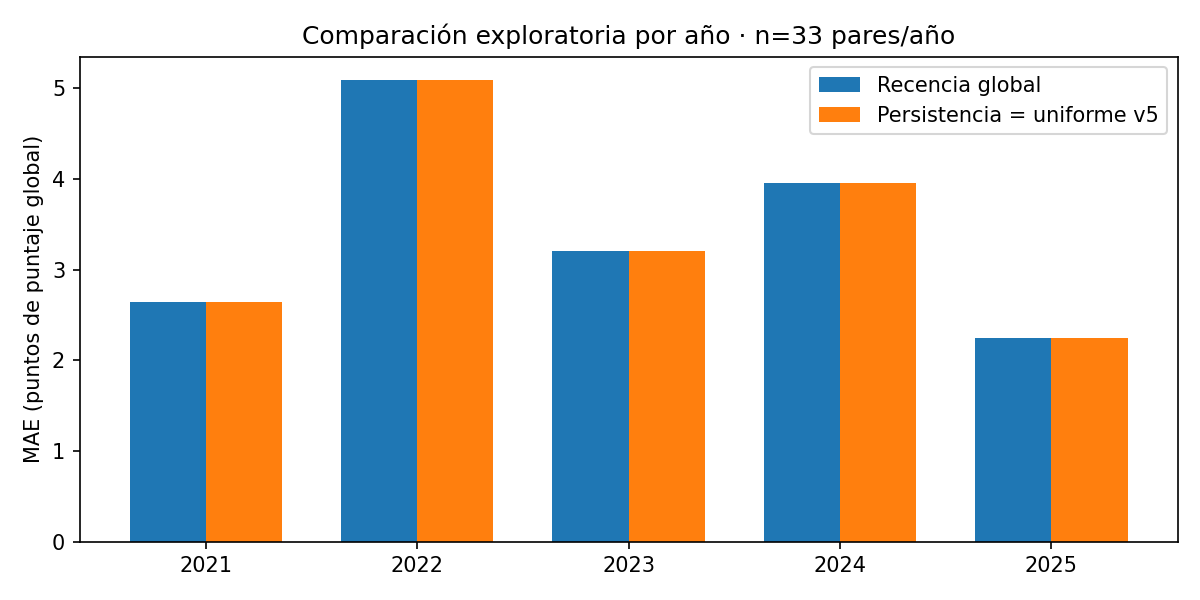

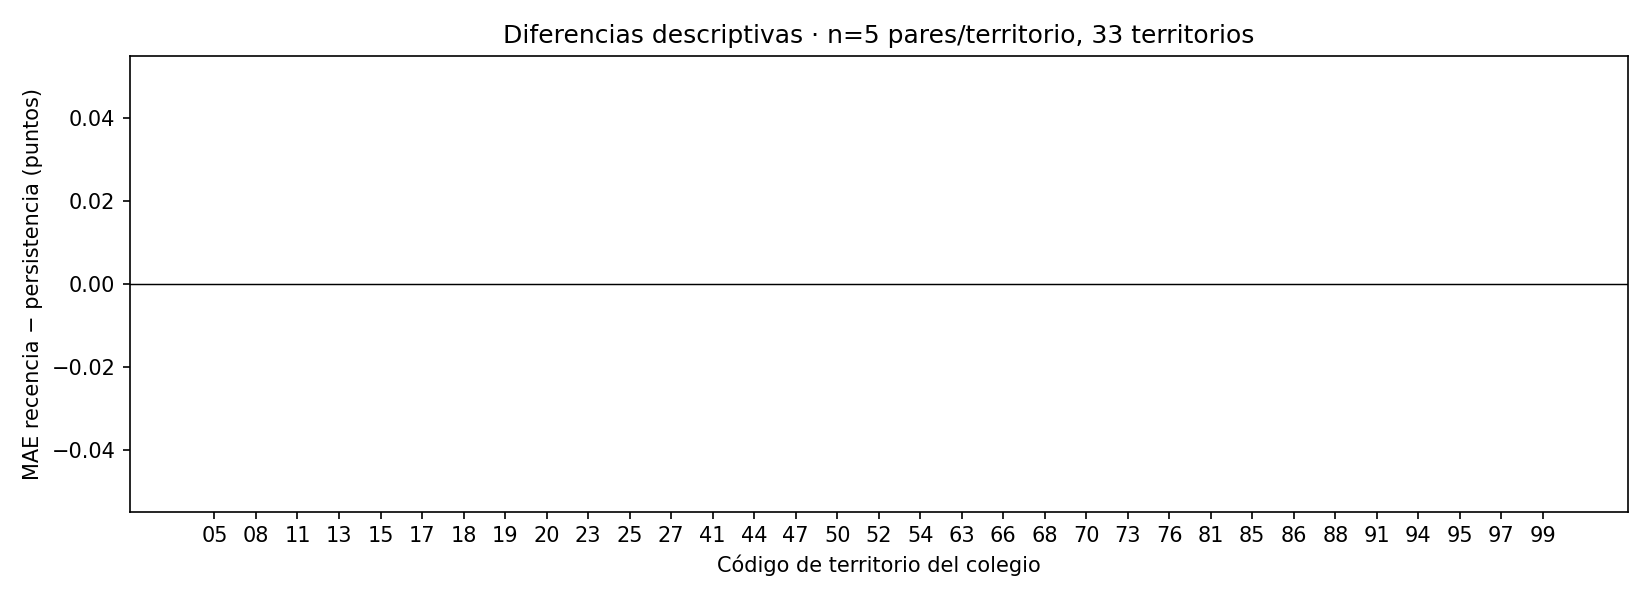

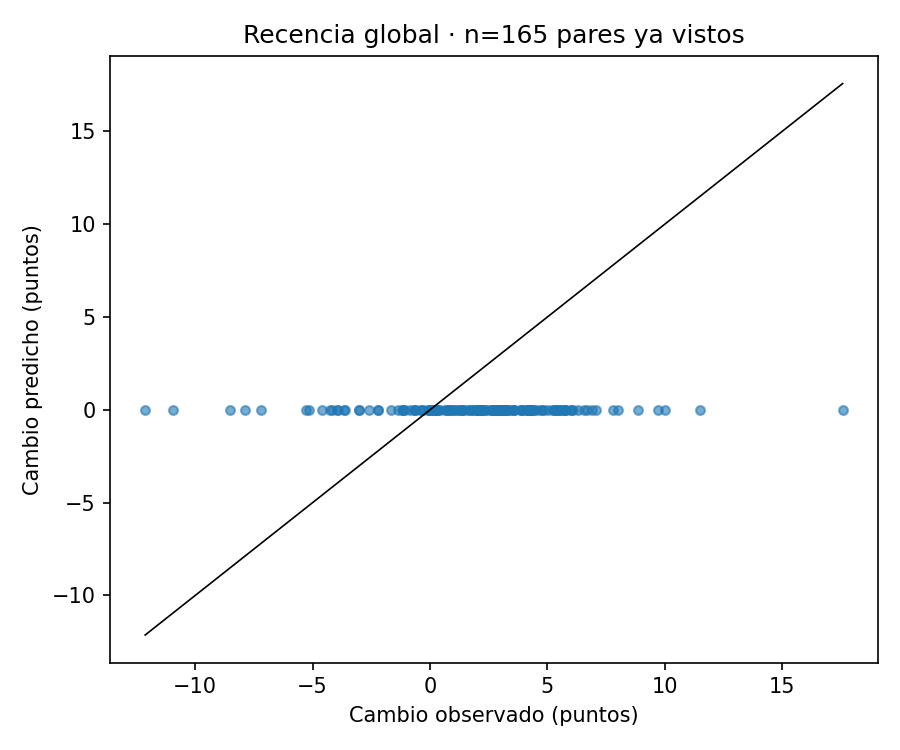

In [6]:
from IPython.display import display,Image
for name in ('mae_por_anio.png','delta_mae_territorio.png','cambios_global.png'):
    display(Image(filename=str(OUT/'graficos'/name)))